## Tephigram with parcel path

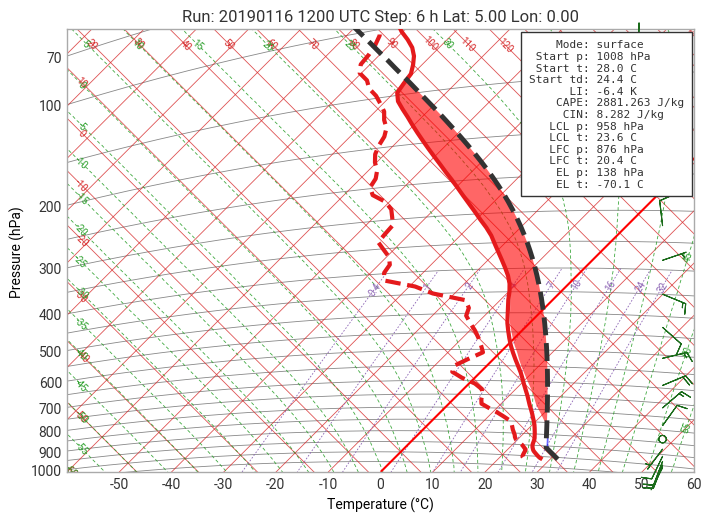

In [1]:
import numpy as np
import earthkit.data as ekd
import earthkit.plots as ekp
from earthkit.meteo import thermo, vertical

data = ekd.from_source(
    "url", "https://sites.ecmwf.int/repository/metview/test-data/gallery/thermo_profile.grib"
)

ds = data.to_xarray()
prof = ds.sel(latitude=5.0, longitude=360.0)

t = prof["t"].values  # K
q = prof["q"].values  # kg/kg
sp = np.exp(prof["lnsp"].values)  # Pa

A, B = vertical.hybrid_level_parameters(137)
p = vertical.pressure_on_hybrid_levels(sp, A, B, levels=prof["level"].values)  # Pa
zh = vertical.height_on_hybrid_levels(t, q, None, sp, A, B, h_type="geopotential", h_reference="ground")
td = thermo.dewpoint_from_specific_humidity(q, p)  # K

cape, cin, extras = thermo.surface_cape_cin(
    p[:-1], t[:-1], q[:-1], zh[:-1],  # profile above the start level
    p[-1], t[-1], q[-1], zh[-1],  # start level
    extra_outputs=["parcel_path"],
)
path = extras["parcel_path"]

log_p = np.log(path.p)
valid = np.isfinite(log_p)
order = np.argsort(log_p[valid])
li = np.interp(np.log(50000.0), log_p[valid][order], (path.tv_env - path.tv)[valid][order])

tephi = ekp.Tephigram(pressure_range=(1015, 100))
tephi.cape_cin(path)

tephi.temperature(t, p=p, units="K", p_units="Pa", linewidth=3)
tephi.dewpoint(td, p=p, units="K", p_units="Pa", linewidth=3)

tephi.parcel(path, linewidth=3.5)

tephi.isotherm(0, color="red")

tephi.wind(prof["u"].values, prof["v"].values, p=p, p_units="Pa", every=4)

field = data.to_fieldlist()[0]
base = field.get("time.base_datetime")
step = int(field.get("time.step").total_seconds() // 3600)
tephi.title(f"Run: {base:%Y%m%d %H%M} UTC Step: {step} h Lat: 5.00 Lon: 0.00")


def fmt_level(name, level):
    if np.isnan(level.p):
        return {}
    return {f"{name} p": f"{level.p / 100:.0f} hPa", f"{name} t": f"{level.t - 273.15:.1f} C"}


# info box (mtext with text_lines)
tephi.info_box(
    {
        "Mode": "surface",
        "Start p": f"{path.origin.p / 100:.0f} hPa",
        "Start t": f"{path.origin.t - 273.15:.1f} C",
        "Start td": f"{td[-1] - 273.15:.1f} C",
        "LI": f"{li:.1f} K",
        "CAPE": f"{cape:.3f} J/kg",
        "CIN": f"{cin:.3f} J/kg",
        **fmt_level("LCL", path.lcl),
        **fmt_level("LFC", path.lfc),
        **fmt_level("EL", path.el),
    },
    loc="upper right",
)

tephi.show()